## Procesamiento y Análisis de Imágenes Térmicas
### Objetivo
Identificar, visualizar y analizar la concentración de calor durante el proceso de deposición láser, eliminando información innecesaria y reduciendo el volumen de datos.

### Integrantes
Junior Anchundia, Jeremy León, Noelia Quishpe

### 0.1 Librerías

In [1]:
# Instalar scikit-image en el entorno del notebook
import sys
import subprocess

resultado = subprocess.run(
    [sys.executable, "-m", "pip", "install", "scikit-image"],
    capture_output=True,
    text=True
)

print("Código de salida:", resultado.returncode)
print(resultado.stdout[-1500:])
print(resultado.stderr[-1500:])

Código de salida: 0
equirement already satisfied: scikit-image in c:\users\juni_\downloads\procesamientoimagenesse-ales_taller1-main\.venv\lib\site-packages (0.26.0)


[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip



In [2]:
from pathlib import Path
import random
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from skimage.filters import threshold_otsu
from sklearn.metrics import silhouette_score  

### 0.2 Directorios

In [3]:
CODE_DIR = Path.cwd().resolve()
PROJECT_ROOT = CODE_DIR.parent
DATA_DIR = PROJECT_ROOT / "Data"
RUTA_DATOS = DATA_DIR / "images"                 # TIFF originales
RUTA_CSV = DATA_DIR / "file.csv"                 # señales del proceso (corriente del láser)
RUTA_SALIDA = DATA_DIR / "salida_taller3_tiff"    # TIFF finales

print("Carpeta de entrada:", RUTA_DATOS)
print("CSV:", RUTA_CSV)
print("Carpeta de salida:", RUTA_SALIDA)

Carpeta de entrada: C:\Users\juni_\Downloads\ProcesamientoImagenesSe-ales_Taller1-main\ProcesamientoImagenesSe-ales_Taller1-main\Data\images
CSV: C:\Users\juni_\Downloads\ProcesamientoImagenesSe-ales_Taller1-main\ProcesamientoImagenesSe-ales_Taller1-main\Data\file.csv
Carpeta de salida: C:\Users\juni_\Downloads\ProcesamientoImagenesSe-ales_Taller1-main\ProcesamientoImagenesSe-ales_Taller1-main\Data\salida_taller3_tiff


### 0.3 Parámetros

In [4]:
# --- Criterio 1: filtrado y ROI -------------------------
UMBRAL_CORRIENTE = 130   # Corriente mínima (láser activo)
TOLERANCIA_MS = 3        # Desfase máximo TIFF ↔ CSV
MODO_ROI = "automatica"  # ROI automática o manual
ROI_MANUAL = None        # Coordenadas si ROI manual
ALFA_ROI = 0.50          # ROI = fondo + α*(pico-fondo)
SIGMA_ROI = 1.5          # Suavizado ligero para ubicar ROI
MARGEN_ROI = 50          # Margen extra para no cortar halo

# --- Criterio 2: máscara -------------------------------
N_EVALUACION = 200       # Frames distribuidos en todo el periodo
SIGMA_IMAGEN = 3         # Suavizado previo a umbralizar
K_MORF = 5               # Kernel morfológico (impar)
SIGMA_MASCARA = 3        # Suavizado de la máscara binaria
T_MANUAL = 5500          # Umbral fijo de referencia
ALFA_MASCARA = 0.25      # Umbral relativo: fondo + α*(pico-fondo)

# Referencias físicas para validar calidad
FRAC_NUCLEO = 0.50       # Núcleo ≥50% rango → conservar
FRAC_HALO = 0.15         # Halo ≤15% rango → eliminar
MIN_NUCLEO_P5 = 95       # En el 5% más difícil, ≥95% núcleo

# Configuración final (None = automática)
CONFIG_MANUAL = None     # Ejemplo: {"metodo":"relativo","morfologia":"cierre","suavizar":True}

# --- Criterio 3: K-means -------------------------------
K_RANGO = range(2, 9)    # Valores de K para el codo
PIXELS_POR_FRAME = 2000  # Muestra de píxeles por frame
K_MIN_VISUAL = 3         # Menos de 3 → pierde gradación
K_MAX_VISUAL = 6         # Más de 6 → difícil distinguir
K_ELEGIDO = None         # None = automático, o entero fijo

SEMILLA = 42             # Reproducibilidad
random.seed(SEMILLA)
rng = np.random.default_rng(SEMILLA)

### 0.4 Funciones base Auxiliares (lectura, ROI y guardado)

In [5]:
def leer_frame(ruta):
    """Lee una imagen (TIFF 16 bits o 8 bits) conservando su profundidad original."""
    img = cv2.imdecode(np.fromfile(str(ruta), dtype=np.uint8), cv2.IMREAD_UNCHANGED)
    if img is None:
        raise IOError(f"No se pudo leer {ruta}")
    return img


def guardar_tiff_gris(img, ruta):
    """Guarda un TIFF de un solo canal (uint8). Usa imencode para soportar rutas con tildes."""
    if img.dtype != np.uint8 or img.ndim != 2:
        raise ValueError("El TIFF debe ser uint8 y de un solo canal")
    ok, buf = cv2.imencode(".tiff", img)
    if not ok:
        raise IOError(f"No se pudo codificar {ruta}")
    buf.tofile(str(ruta))


def disco(r):
    """Elemento estructurante circular de radio r."""
    y, x = np.ogrid[-r:r + 1, -r:r + 1]
    return x**2 + y**2 <= r**2

In [6]:
def calcular_roi(img):
    """Devuelve (r0, r1, c0, c1) o None si el frame no tiene señal.
    Automática: se marca todo lo que supera 'fondo + ALFA_ROI*(pico-fondo)', se cierran
    pequeños huecos, y se toma el rectángulo que contiene esa zona + MARGEN_ROI.
    El fondo es la mediana del frame completo (casi todo es negro, por eso es un buen fondo).
    """
    if MODO_ROI == "manual":
        if ROI_MANUAL is None:
            raise ValueError("MODO_ROI='manual' requiere definir ROI_MANUAL")
        return tuple(int(v) for v in ROI_MANUAL)

    fondo, pico = float(np.median(img)), float(img.max())
    if pico <= fondo:                      # imagen plana o toda en cero -> sin información
        return None

    suave = ndi.gaussian_filter(img.astype(np.float32), SIGMA_ROI)
    zona = suave > fondo + ALFA_ROI * (pico - fondo)
    zona = ndi.binary_closing(zona, structure=disco(5))   # une zonas calientes separadas
    zona = ndi.binary_fill_holes(zona)
    filas, cols = np.where(zona)
    if filas.size == 0:
        return None

    alto, ancho = img.shape[:2]
    return (max(int(filas.min()) - MARGEN_ROI, 0), min(int(filas.max()) + MARGEN_ROI + 1, alto),
            max(int(cols.min()) - MARGEN_ROI, 0),  min(int(cols.max()) + MARGEN_ROI + 1, ancho))


def preparar_frame(ruta):
    """Lee un TIFF y devuelve un diccionario con recorte, fondo, pico y ROI (o None si no hay señal)."""
    img = leer_frame(ruta)
    roi = calcular_roi(img)
    if roi is None:
        return None
    r0, r1, c0, c1 = roi
    r0, r1, c0, c1 = max(r0, 0), min(r1, img.shape[0]), max(c0, 0), min(c1, img.shape[1])
    if r1 <= r0 or c1 <= c0:
        raise ValueError(f"ROI inválida: {roi}")
    recorte = img[r0:r1, c0:c1]
    if recorte.max() == 0:
        return None
    return {"img": img, "recorte": recorte, "roi": (r0, r1, c0, c1),
            "fondo": float(np.median(img)), "pico": float(img.max())}

## 1. Filtrar imágenes con láser activo y recortar la ROI

**Regla de láser activo** (vista en clase): `LDM4000_Current_Monitor_1 > 130` **y** `LDM4000_Current_Monitor_2 > 130`.

#### 1.1 Leer el CSV y marcar el láser activo

In [7]:
df_csv = pd.read_csv(RUTA_CSV)
df_csv["deposito_activo"] = (
    (df_csv["LDM4000_Current_Monitor_1"] > UMBRAL_CORRIENTE) &
    (df_csv["LDM4000_Current_Monitor_2"] > UMBRAL_CORRIENTE)
)
print("Filas totales de CSV:      ", len(df_csv))
print("Filas con depósito activo: ", int(df_csv["deposito_activo"].sum()))
print("Filas sin depósito:        ", int((~df_csv["deposito_activo"]).sum()))

Filas totales de CSV:       58708
Filas con depósito activo:  27677
Filas sin depósito:         31031


#### 1.3 Vincular cada TIFF con el CSV

El nombre del TIFF es su instante en milisegundos. Para cada TIFF se busca la fila del CSV más cercana dentro de `±TOLERANCIA_MS`. Si hay dos filas igual de cercanas el caso es **ambiguo** y se descarta.

In [8]:
# Diccionario {milisegundo: ¿activo?} construido a partir del CSV
por_ms = {}
for tiempo, activo in zip(df_csv["timestamp*"], df_csv["deposito_activo"]):
    if pd.isna(tiempo):
        continue
    por_ms.setdefault(int(round(float(tiempo) * 1000)), bool(activo))

# Lista de TIFF ordenados por nombre (= orden temporal)
rutas_tiff = sorted(p for p in RUTA_DATOS.iterdir()
                    if p.is_file() and p.suffix.lower() in (".tif", ".tiff"))
print("Archivos TIFF encontrados:", len(rutas_tiff))

Archivos TIFF encontrados: 41645


In [9]:
def emparejar_tiff(ruta):
    """Devuelve (estado, ms_csv, desfase). estado: 'activo' | 'inactivo' | 'sin_correspondencia' | 'ambiguo'."""
    try:
        ms_archivo = int(ruta.stem)
    except ValueError:
        return "sin_correspondencia", None, None
    candidatos = [(abs(d), ms_archivo + d) for d in range(-TOLERANCIA_MS, TOLERANCIA_MS + 1)
                  if ms_archivo + d in por_ms]
    if not candidatos:
        return "sin_correspondencia", None, None
    menor = min(c[0] for c in candidatos)
    mejores = [c for c in candidatos if c[0] == menor]
    if len(mejores) != 1:
        return "ambiguo", None, menor
    ms_csv = mejores[0][1]
    return ("activo" if por_ms[ms_csv] else "inactivo"), ms_csv, menor


registros_deposito, conteo = [], {"activo": 0, "inactivo": 0, "sin_correspondencia": 0, "ambiguo": 0}
for ruta in rutas_tiff:
    estado, ms_csv, desfase = emparejar_tiff(ruta)
    conteo[estado] += 1
    if estado == "activo":
        registros_deposito.append({"ruta": ruta, "ms_csv": ms_csv, "desfase_ms": desfase})

print("TIFF con depósito activo (se conservan):", conteo["activo"])
print("TIFF sin depósito (se descartan):       ", conteo["inactivo"])
print("TIFF sin correspondencia en el CSV:     ", conteo["sin_correspondencia"])
print("TIFF ambiguos (se descartan):           ", conteo["ambiguo"])
print(f"Reducción del dataset por filtro de láser: {100*(1 - conteo['activo']/max(len(rutas_tiff),1)):.1f} %")

TIFF con depósito activo (se conservan): 18624
TIFF sin depósito (se descartan):        20896
TIFF sin correspondencia en el CSV:      0
TIFF ambiguos (se descartan):            2125
Reducción del dataset por filtro de láser: 55.3 %


#### 1.4 Comprobación visual de la ROI

Se revisan 5 frames al azar con láser activo. La ROI debe encerrar toda la zona caliente con algo de margen, sin cortar el halo y sin incluir demasiado fondo negro.

1764596756481.tiff | Δt = 1 ms | ROI = (180, 376, 302, 502) | tamaño = (196, 200)


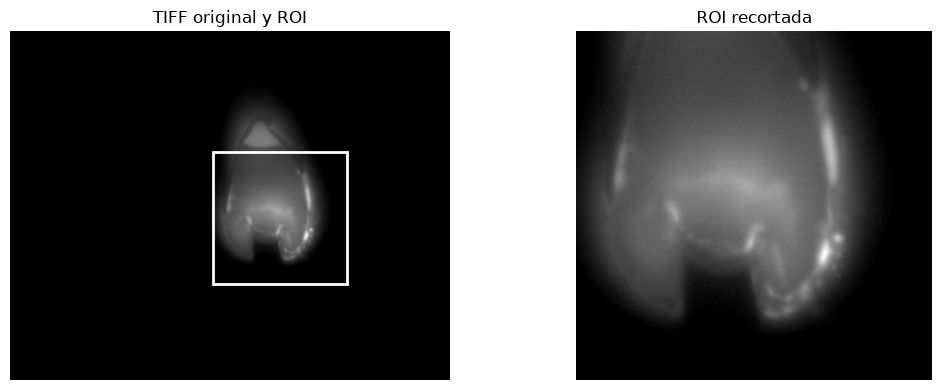

1764596717913.tiff | Δt = 1 ms | ROI = (87, 370, 271, 489) | tamaño = (283, 218)


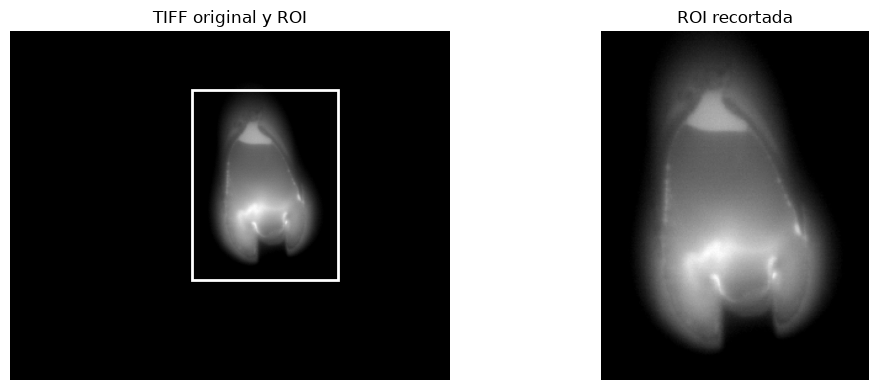

1764596814494.tiff | Δt = 2 ms | ROI = (81, 366, 252, 478) | tamaño = (285, 226)


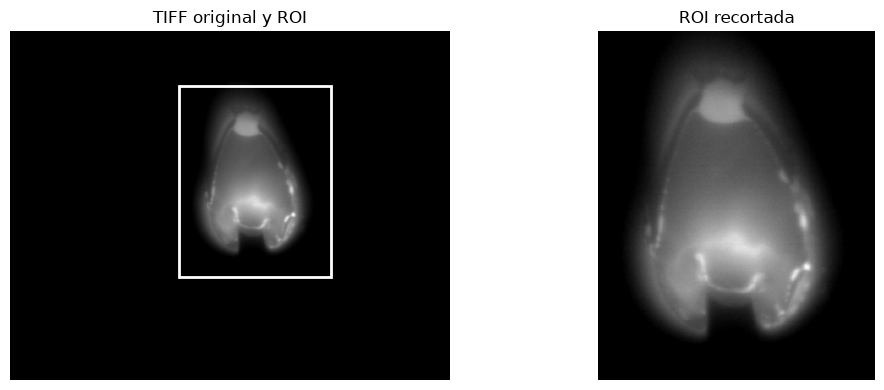

1764596806806.tiff | Δt = 0 ms | ROI = (82, 373, 265, 495) | tamaño = (291, 230)


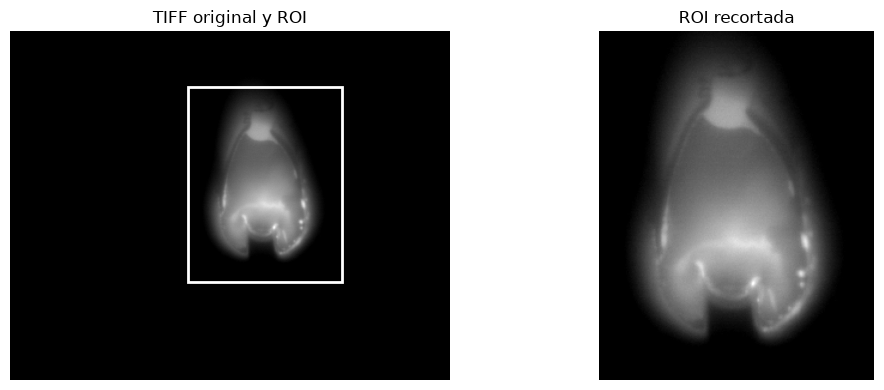

1764596801349.tiff | Δt = 1 ms | ROI = (95, 379, 270, 497) | tamaño = (284, 227)


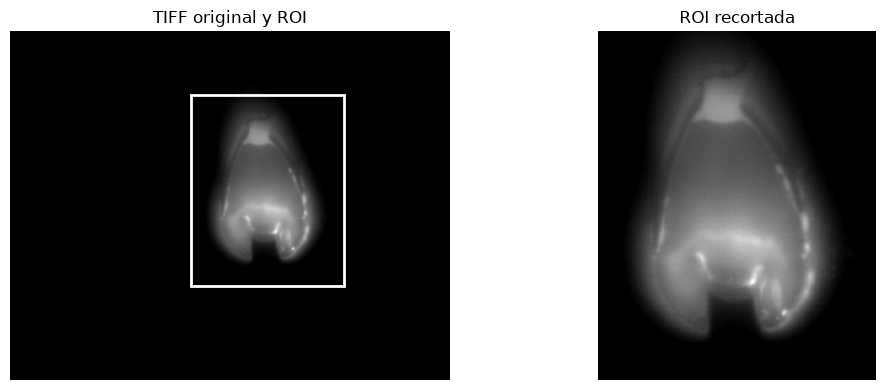

In [10]:
def mostrar_roi(frame):
    r0, r1, c0, c1 = frame["roi"]
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].imshow(frame["img"], cmap="gray")
    ax[0].add_patch(plt.Rectangle((c0, r0), c1 - c0, r1 - r0, fill=False, ec="white", lw=2))
    ax[0].set_title("TIFF original y ROI")
    ax[1].imshow(frame["recorte"], cmap="gray")
    ax[1].set_title("ROI recortada")
    for a in ax: a.axis("off")
    plt.tight_layout(); plt.show()


for reg in random.sample(registros_deposito, min(5, len(registros_deposito))):
    frame = preparar_frame(reg["ruta"])
    if frame is None:
        print(reg["ruta"].name, "-> sin señal");  continue
    print(f"{reg['ruta'].name} | Δt = {reg['desfase_ms']} ms | ROI = {frame['roi']} | tamaño = {frame['recorte'].shape}")
    mostrar_roi(frame)

## 2. Máscara sin halo: umbral + morfología + suavizado

Alrededor de la zona caliente hay un *halo* difuso de baja intensidad que no aporta información del proceso. Una buena máscara conserva el **núcleo** caliente y descarta el halo, con un contorno **suave** (sin dientes).

**Se propone las siguientes combinaciones**:

| Decisión | Opciones | Por qué |
|---|---|---|
| Umbral | `otsu`, `otsu_2pasos`, `relativo`, `manual` | Otsu se adapta a cada frame; `otsu_2pasos` repite Otsu solo sobre lo que ya no es fondo (para separar halo de cuerpo); `relativo` usa un % del rango del frame; `manual` es el valor fijo anterior (línea base) |
| Morfología | `ninguna`, `apertura`, `cierre`, `apertura_cierre` | Apertura quita ruido pequeño; cierre une separaciones. |
| Suavizado de máscara | `True`, `False` | Evita bordes escalonados |

En todas se rellenan huecos y se conserva solo la **componente conexa mayor** (la huella principal), porque restos aislados no son parte de la zona de depósito.

#### 2.1 Funciones para construir la máscara

In [11]:
def calcular_umbral(img_suave, metodo, fondo, pico):
    """Calcula el umbral según el método elegido. Trabaja sobre la imagen ya suavizada."""
    if metodo == "otsu":
        return threshold_otsu(img_suave)
    if metodo == "otsu_2pasos":
        t1 = threshold_otsu(img_suave)               # 1er Otsu: separa fondo oscuro del resto
        resto = img_suave[img_suave > t1]            # 2º Otsu solo sobre el objeto (cuerpo + halo)
        return threshold_otsu(resto) if resto.size > 1 and resto.min() < resto.max() else t1
    if metodo == "relativo":
        return fondo + ALFA_MASCARA * (pico - fondo)
    if metodo == "manual":
        return float(T_MANUAL)
    raise ValueError(f"Método no válido: {metodo}")


def aplicar_morfologia(m, morfologia, k_morf):
    """Aplica la operación morfológica con un kernel elíptico (bordes más naturales que un cuadrado)."""
    if morfologia == "ninguna":
        return m
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k_morf, k_morf))
    ape = lambda x: cv2.morphologyEx(x, cv2.MORPH_OPEN, kernel)
    cie = lambda x: cv2.morphologyEx(x, cv2.MORPH_CLOSE, kernel)
    if morfologia == "apertura":
        return ape(m)
    if morfologia == "cierre":
        return cie(m)
    if morfologia == "apertura_cierre":
        return cie(ape(m))
    raise ValueError(f"Morfología no válida: {morfologia}")


def componente_mayor(m):
    """Conserva solo la región conectada más grande (la huella principal)."""
    n, etiquetas, stats, _ = cv2.connectedComponentsWithStats(m.astype(np.uint8))
    if n <= 1:
        return np.zeros_like(m, dtype=np.uint8)
    mayor = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
    return (etiquetas == mayor).astype(np.uint8)


def suavizar_mascara(m, sigma):
    """Desenfoca la máscara y la vuelve a binarizar en 0.5: redondea esquinas y quita dientes."""
    return (ndi.gaussian_filter(m.astype(np.float32), sigma) > 0.5).astype(np.uint8)

In [12]:
def construir_mascara(frame, metodo, morfologia, suavizar,
                      sigma_imagen=None, k_morf=None, sigma_mascara=None):
    """Cadena completa: suavizar imagen -> umbral -> morfología -> rellenar -> componente mayor -> suavizar máscara."""
    sigma_imagen = SIGMA_IMAGEN if sigma_imagen is None else sigma_imagen
    k_morf = K_MORF if k_morf is None else k_morf
    sigma_mascara = SIGMA_MASCARA if sigma_mascara is None else sigma_mascara

    recorte = frame["recorte"]
    img_suave = ndi.gaussian_filter(recorte.astype(np.float32), sigma_imagen)   # float32: evita redondeo de uint16
    if img_suave.max() == img_suave.min():
        return np.zeros(recorte.shape, np.uint8)

    umbral = calcular_umbral(img_suave, metodo, frame["fondo"], frame["pico"])
    m = (img_suave > umbral).astype(np.uint8)
    m = aplicar_morfologia(m, morfologia, k_morf)
    m = ndi.binary_fill_holes(m).astype(np.uint8)
    m = componente_mayor(m)
    if suavizar:
        m = componente_mayor(suavizar_mascara(m, sigma_mascara))
    return m


def limpiar_con_mascara(recorte, mascara):
    """Deja la intensidad original dentro de la máscara y 0 fuera."""
    return np.where(mascara > 0, recorte, 0).astype(recorte.dtype)

#### 2.2 Indicadores para medir una máscara

| Indicador | Qué mide | Objetivo |
|---|---|---|
| `nucleo_cubierto` (%) | Del núcleo, cuánto conserva la máscara | Alto (≈100) |
| `halo_en_mascara` (%) | De la máscara, cuánto es halo | Bajo |
| `rugosidad` | Perímetro² / (4π·área). Vale 1 en un círculo perfecto y sube con bordes irregulares | Bajo (suave) |
| `pct_roi` (%) | Tamaño de la máscara respecto a la ROI | Estable, ni vacía ni toda la ROI |

In [13]:
def perimetro(m):
    contornos, _ = cv2.findContours(m.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    return sum(cv2.arcLength(c, True) for c in contornos)


def evaluar_mascara(mascara, frame):
    """Calcula los indicadores de una máscara respecto a las referencias físicas del frame."""
    recorte = frame["recorte"].astype(np.float32)
    rango = frame["pico"] - frame["fondo"]
    nucleo = recorte > frame["fondo"] + FRAC_NUCLEO * rango
    halo = recorte <= frame["fondo"] + FRAC_HALO * rango
    dentro = mascara > 0
    area = int(dentro.sum())
    return {
        "pct_roi": 100 * area / mascara.size,
        "nucleo_cubierto": 100 * (dentro & nucleo).sum() / nucleo.sum() if nucleo.any() else np.nan,
        "halo_en_mascara": 100 * (dentro & halo).sum() / area if area else np.nan,
        "rugosidad": perimetro(mascara) ** 2 / (4 * np.pi * area) if area else np.nan,
        "mascara_vacia": int(area == 0),
    }

#### 2.3 Muestra amplia de evaluación

Se toman `N_EVALUACION` frames **repartidos uniformemente en todo el periodo** (inicio, medio y final del proceso), porque el comportamiento térmico cambia durante la deposición. Los recortes se cargan **una sola vez** y se reutilizan para todas las combinaciones.

In [14]:
n = min(N_EVALUACION, len(registros_deposito))
indices = np.linspace(0, len(registros_deposito) - 1, n).astype(int)
muestra_evaluacion, frames_muestra = [], []
for i in indices:
    reg = registros_deposito[i]
    frame = preparar_frame(reg["ruta"])
    if frame is None:
        continue
    frame["archivo"] = reg["ruta"].name
    frame.pop("img")                    # no se necesita la imagen completa: ahorra memoria
    frames_muestra.append(frame)
    muestra_evaluacion.append(reg)

print("Frames en la muestra de evaluación:", len(frames_muestra))

Frames en la muestra de evaluación: 200


#### 2.4 Probar todas las combinaciones

4 umbrales × 4 morfologías × 2 (con/sin suavizado) = **32 configuraciones**, cada una sobre toda la muestra.

In [15]:
metodos = ["otsu", "otsu_2pasos", "relativo", "manual"]
morfologias = ["ninguna", "apertura", "cierre", "apertura_cierre"]
suavizados = [False, True]
configuraciones = [(m, mo, s) for m in metodos for mo in morfologias for s in suavizados]
print("Configuraciones a evaluar:", len(configuraciones))

Configuraciones a evaluar: 32


In [16]:
filas = []
for frame in frames_muestra:
    for metodo, morfologia, suavizar in configuraciones:
        mascara = construir_mascara(frame, metodo, morfologia, suavizar)
        fila = evaluar_mascara(mascara, frame)
        fila.update({"archivo": frame["archivo"], "metodo": metodo,
                     "morfologia": morfologia, "suavizar": suavizar})
        filas.append(fila)
df_eval = pd.DataFrame(filas)
print("Evaluaciones realizadas:", len(df_eval))

Evaluaciones realizadas: 6400


#### 2.6 Regla de selección

La mejor configuración cumple, **en orden**:

1. Ninguna máscara vacía.
2. Conserva el núcleo incluso en los casos difíciles (`nucleo_p5 ≥ MIN_NUCLEO_P5`).
3. De las que cumplen, la de **menos halo** retenido.
4. En empate (diferencia < 1 punto en halo), la de **contorno más suave** (menor rugosidad, redondeada a 2 decimales).
5. Si aún hay empate, se prefiere la que **usa suavizado** (lo pide la rúbrica) y la **morfología más simple**.

Así se evita el error de elegir la máscara más pequeña sin comprobar que sigue conteniendo la zona de interés.

In [17]:
claves = ["metodo", "morfologia", "suavizar"]
resumen = df_eval.groupby(claves).agg(
    nucleo_medio=("nucleo_cubierto", "mean"),
    nucleo_p5=("nucleo_cubierto", lambda s: np.nanpercentile(s, 5)),
    halo_en_mascara=("halo_en_mascara", "mean"),
    rugosidad=("rugosidad", "mean"),
    pct_roi=("pct_roi", "mean"),
    pct_vacias=("mascara_vacia", lambda s: 100 * s.mean()),
).reset_index()

In [18]:
validas = resumen[(resumen["pct_vacias"] == 0) & (resumen["nucleo_p5"] >= MIN_NUCLEO_P5)].copy()

# Agrupar en "bandas" de 1 punto de halo para que el desempate use la rugosidad
validas["banda_halo"] = (validas["halo_en_mascara"] // 1)
validas["rugosidad_2d"] = validas["rugosidad"].round(2)
orden_morf = {"ninguna": 0, "apertura": 1, "cierre": 2, "apertura_cierre": 3}   # de más simple a más compleja
validas["complejidad"] = validas["morfologia"].map(orden_morf)
mejores = validas.sort_values(["banda_halo", "rugosidad_2d", "suavizar", "complejidad"],
                              ascending=[True, True, False, True]).reset_index(drop=True)
print("Top 5 configuraciones válidas:")
print(mejores.drop(columns=["banda_halo", "rugosidad_2d", "complejidad"]).head(5).round(2).to_string(index=False))

if CONFIG_MANUAL is not None:
    CONFIG_FINAL = dict(CONFIG_MANUAL)
    print("\nSe usa la configuración forzada por el usuario:", CONFIG_FINAL)
else:
    top = mejores.iloc[0]
    CONFIG_FINAL = {"metodo": top["metodo"], "morfologia": top["morfologia"], "suavizar": bool(top["suavizar"])}
    print("\nConfiguración final elegida automáticamente:", CONFIG_FINAL)

Top 5 configuraciones válidas:
metodo      morfologia  suavizar  nucleo_medio  nucleo_p5  halo_en_mascara  rugosidad  pct_roi  pct_vacias
  otsu         ninguna      True         100.0      100.0             0.00       1.49     35.4         0.0
  otsu        apertura      True         100.0      100.0             0.00       1.49     35.4         0.0
  otsu          cierre      True         100.0      100.0             0.00       1.49     35.4         0.0
  otsu apertura_cierre      True         100.0      100.0             0.00       1.49     35.4         0.0
manual         ninguna      True         100.0      100.0             0.12       1.50     35.1         0.0

Configuración final elegida automáticamente: {'metodo': 'otsu', 'morfologia': 'ninguna', 'suavizar': True}


#### 2.8 Comparación visual

Se muestran tres frames (inicio, medio y final) con dos contornos sobre la imagen:

- **rojo** = umbral fijo anterior (`manual`, T = 5500, sin morfología);
- **cian** = configuración final.

La imagen se muestra con una corrección gamma (`**0.5`) que realza las zonas tenues, para poder ver el halo; el contorno no depende de esa visualización.

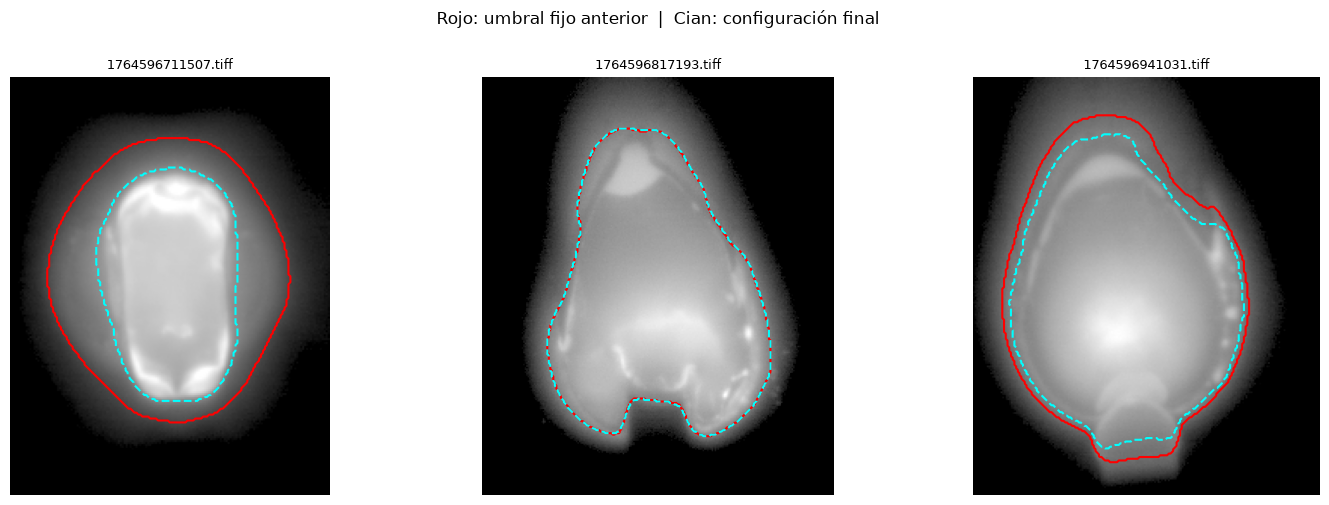

In [19]:
def mostrar_contornos(frames, config):
    fig, ax = plt.subplots(1, len(frames), figsize=(5 * len(frames), 5), squeeze=False)
    for a, frame in zip(ax[0], frames):
        base = frame["recorte"].astype(np.float32)
        a.imshow(np.clip(base / frame["pico"], 0, 1) ** 0.5, cmap="gray")

        # Máscara anterior (umbral fijo) y nueva (configuración final)
        m_old = construir_mascara(frame, "manual", "ninguna", False)
        m_new = construir_mascara(frame, config["metodo"], config["morfologia"], config["suavizar"])

        # Dibujar contornos: rojo continuo, cian entrecortado
        if m_old.any() and not m_old.all():
            a.contour(m_old, levels=[0.5], colors="red", linewidths=1.5, linestyles="-")
        if m_new.any() and not m_new.all():
            a.contour(m_new, levels=[0.5], colors="cyan", linewidths=1.5, linestyles="--")

        a.set_title(frame["archivo"], fontsize=9)
        a.axis("off")

    fig.suptitle("Rojo: umbral fijo anterior  |  Cian: configuración final", y=1.0)
    plt.tight_layout()
    plt.show()

ids = sorted({0, len(frames_muestra) // 2, len(frames_muestra) - 1})
mostrar_contornos([frames_muestra[i] for i in ids], CONFIG_FINAL)

#### 2.9 Casos difíciles

Una configuración se valida mirando **los peores casos**, no solo los buenos. Se muestran los 3 frames donde la configuración final conserva menos núcleo.

           archivo  nucleo_cubierto  halo_en_mascara  pct_roi
1764596711507.tiff            100.0              0.0    20.26
1764596712219.tiff            100.0              0.0    44.44
1764596712965.tiff            100.0              0.0    35.24


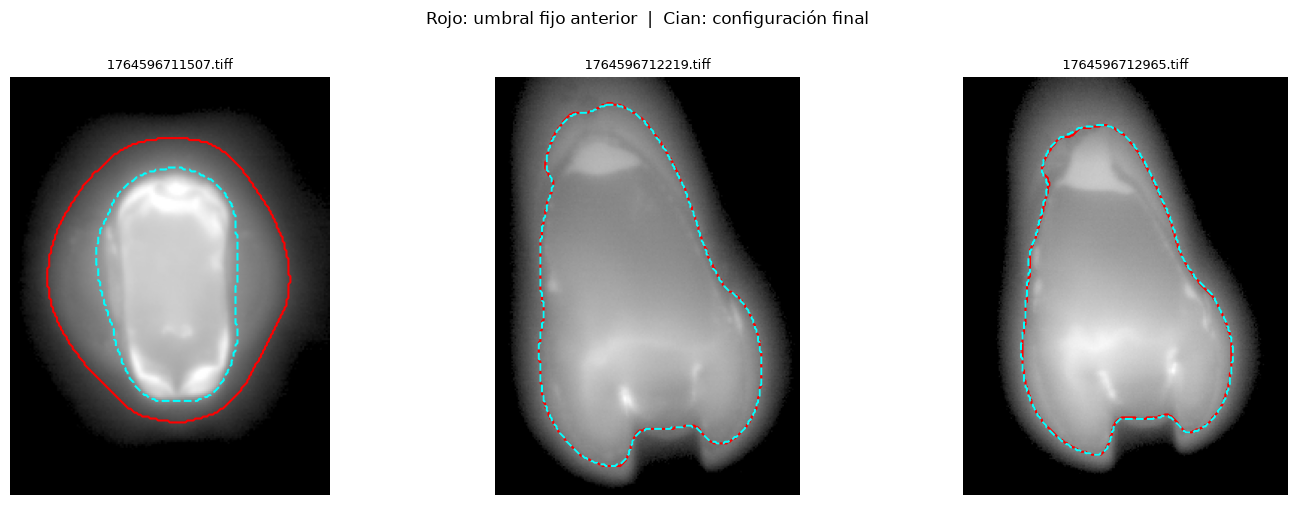

In [20]:
df_final = df_eval[(df_eval["metodo"] == CONFIG_FINAL["metodo"]) &
                   (df_eval["morfologia"] == CONFIG_FINAL["morfologia"]) &
                   (df_eval["suavizar"] == CONFIG_FINAL["suavizar"])]
peores = df_final.sort_values("nucleo_cubierto").head(3)
print(peores[["archivo", "nucleo_cubierto", "halo_en_mascara", "pct_roi"]].round(2).to_string(index=False))
por_nombre = {f["archivo"]: f for f in frames_muestra}
mostrar_contornos([por_nombre[a] for a in peores["archivo"]], CONFIG_FINAL)

#### 2.11 Conclusión del criterio 2

- La **línea base `manual` (T = 5500)** se mantiene solo para comparar. En la versión anterior del notebook este umbral retenía ~67 % de píxeles débiles y su contorno quedaba bien alejado del objeto, y los centros de K-means de ese conjunto (~7 000 y ~11 000 frente a un pico cercano a 43 000) confirmaban que había mucho halo dentro de la máscara. Un umbral fijo tampoco se adapta a los cambios de intensidad entre frames, mientras que Otsu y el umbral relativo se recalculan en cada imagen.
- La configuración final se eligió por regla (sección 2.6) y no por apariencia. **Al ejecutar con el dataset real, anotar aquí** qué configuración salió, su `nucleo_p5` y su `halo_en_mascara`, y confirmar con 2.8 y 2.9 que visualmente el contorno cian queda sobre el borde del objeto y no sobre el halo.
- El **suavizado de la máscara** se evalúa en 2.7: se justifica si baja la rugosidad sin perder núcleo. Si no cambia nada, se deja activado igualmente porque la rúbrica lo pide y no perjudica.
- La **componente conexa mayor** y el **relleno de huecos** se aplican siempre, porque un depósito es una sola huella continua.
- Limitación: no hay máscaras dibujadas a mano, y la evaluación se basa en umbrales físicos (50 % y 15 %) asumidos. Por eso las conclusiones se respaldan con la comparación visual (2.8 y 2.9).

## 3. K-means: ¿cuántos rangos de intensidad (K)?

K-means agrupa los píxeles **solo por su intensidad** (1 dato por píxel). Cada grupo es un rango térmico (de frío a caliente) que se muestra como un nivel de gris.

**¿Cómo se elige K?** Con dos criterios objetivos y uno visual:

1. **Método del codo** (inercia): la inercia (suma de distancias al centro de su grupo) siempre baja al aumentar K. Interesa el punto donde **deja de bajar de forma importante**.
2. **Coeficiente de silueta**: entre −1 y 1; mide qué tan bien separados están los grupos. Más alto es mejor. En datos de una sola variable suele bajar al subir K, por eso se usa como verificación (¿los grupos siguen bien definidos?) y no como único criterio.
3. **Comprobación visual**: más K no ayuda si los niveles de gris dejan de distinguirse.

Los píxeles de entrenamiento salen **solo de dentro de la máscara final**, así el halo (ya eliminado) no distorsiona los rangos. Se entrena **un solo modelo** con muchos frames para que el mismo nivel de gris signifique la misma temperatura en todos los TIFF de salida.

#### 3.1 Reunir los píxeles de entrenamiento

In [21]:
def pixeles_dentro_mascara(frame, config, n_max):
    """Devuelve una muestra aleatoria de intensidades de los píxeles dentro de la máscara."""
    mascara = construir_mascara(frame, **config)
    valores = frame["recorte"][mascara > 0].astype(np.float32)
    if len(valores) > n_max:
        valores = rng.choice(valores, size=n_max, replace=False)
    return valores

muestras = [pixeles_dentro_mascara(f, CONFIG_FINAL, PIXELS_POR_FRAME) for f in frames_muestra]
X = np.concatenate([m for m in muestras if m.size]).reshape(-1, 1)
print("Píxeles de entrenamiento:", len(X))
print(f"Intensidad: mín = {X.min():.0f} | mediana = {np.median(X):.0f} | máx = {X.max():.0f}")

Píxeles de entrenamiento: 400000
Intensidad: mín = 3776 | mediana = 9488 | máx = 65520


#### 3.2 Entrenar K-means para cada K

Se usa inicialización `KMEANS_PP_CENTERS` (centros iniciales bien repartidos) y 5 reinicios; se conserva el mejor resultado. Se calcula la inercia y la silueta (esta última sobre una submuestra de 10 000 píxeles, porque es costosa).

In [22]:
def ajustar_kmeans(X, k, reinicios=5):
    criterio = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 50, 0.1)
    inercia, etiquetas, centros = cv2.kmeans(X, k, None, criterio, reinicios, cv2.KMEANS_PP_CENTERS)
    return float(inercia), etiquetas.ravel(), np.sort(centros.ravel())


idx_sil = rng.choice(len(X), size=min(10000, len(X)), replace=False)   # submuestra para la silueta
resultados_k, modelos_k = [], {}
for k in K_RANGO:
    inercia, etiquetas, centros = ajustar_kmeans(X, k)
    sil = silhouette_score(X[idx_sil], etiquetas[idx_sil])
    modelos_k[k] = centros
    resultados_k.append({"K": k, "inercia": inercia, "silueta": sil})

df_k = pd.DataFrame(resultados_k)

def detectar_codo(df):
    """Codo geométrico: el punto de la curva de inercia más alejado de la recta que une el primer y el último K.
    Ambos ejes se normalizan a [0, 1] para que la distancia no dependa de las unidades."""
    x = (df["K"] - df["K"].min()) / (df["K"].max() - df["K"].min())
    y = (df["inercia"] - df["inercia"].min()) / (df["inercia"].max() - df["inercia"].min())
    return int(df["K"].iloc[int(np.argmax(1 - x - y))])   # recta x + y = 1; la curva queda por debajo de ella

k_codo_bruto = detectar_codo(df_k)
# Ganancia de añadir el K-ésimo grupo: cuánto baja la inercia respecto a K-1
df_k["ganancia_%"] = 100 * (df_k["inercia"].shift(1) - df_k["inercia"]) / df_k["inercia"].shift(1)
print(df_k.round(3).to_string(index=False))

 K      inercia  silueta  ganancia_%
 2 2.864440e+12    0.606         NaN
 3 1.390448e+12    0.615      51.458
 4 7.561290e+11    0.584      45.620
 5 5.092517e+11    0.570      32.650
 6 3.959539e+11    0.532      22.248
 7 3.136725e+11    0.532      20.781
 8 2.371179e+11    0.526      24.406


#### 3.3 Gráficas del codo y la silueta

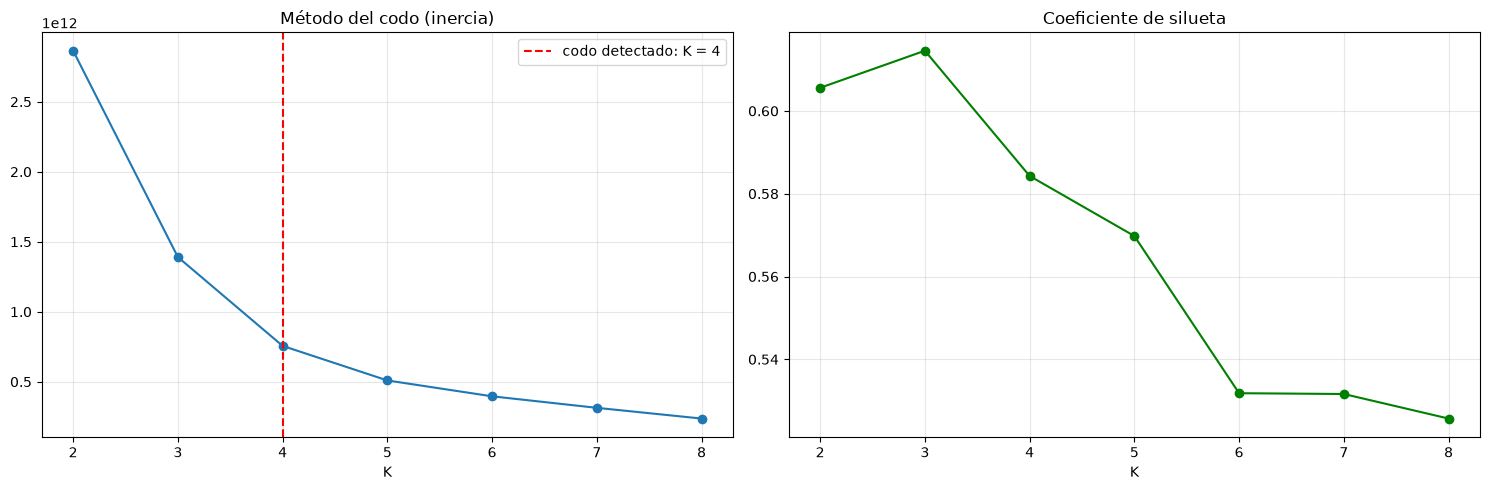

In [23]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].plot(df_k["K"], df_k["inercia"], "o-"); ax[0].set_title("Método del codo (inercia)")
ax[0].axvline(k_codo_bruto, color="red", ls="--", label=f"codo detectado: K = {k_codo_bruto}"); ax[0].legend()
ax[1].plot(df_k["K"], df_k["silueta"], "o-", color="green"); ax[1].set_title("Coeficiente de silueta")
for a in ax: a.set_xlabel("K"); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

#### 3.4 Regla para elegir K

"Buscar el codo a ojo" no es reproducible, así que se detecta de forma geométrica (`detectar_codo`, sección 3.2): se traza una recta entre el primer y el último punto de la curva de inercia y se toma el punto más alejado de ella. Ese punto es donde la curva pasa de bajar rápido a bajar lento.

Después se limita el resultado a `[K_MIN_VISUAL, K_MAX_VISUAL]` (entre 3 y 6 grises): con 2 solo se distingue "frío / caliente" y con más de 6 los grises no se distinguen visualmente.

Un umbral fijo de ganancia (por ejemplo "mínimo 15 %") no se usa porque en datos de una sola variable la inercia sigue bajando más de ese porcentaje aunque se añadan muchos grupos, y esa regla siempre elegiría el máximo.

In [24]:
k_codo = int(np.clip(k_codo_bruto, K_MIN_VISUAL, K_MAX_VISUAL))

K_FINAL = int(K_ELEGIDO) if K_ELEGIDO is not None else k_codo
print("Codo detectado:", k_codo_bruto, "| ajustado al rango visual:", k_codo)
print("K usado:", K_FINAL, "(forzado por el usuario)" if K_ELEGIDO is not None else "(automático)")
print("Silueta con K final:", round(float(df_k.loc[df_k['K'] == K_FINAL, 'silueta'].iloc[0]), 3))
print("Centros de intensidad (frío -> caliente):", np.round(modelos_k[K_FINAL]).astype(int).tolist())

Codo detectado: 4 | ajustado al rango visual: 4
K usado: 4 (automático)
Silueta con K final: 0.584
Centros de intensidad (frío -> caliente): [7317, 11063, 15394, 43046]


#### 3.5 Asignar cada píxel a un rango y mostrarlo en grises

Con los centros ordenados se calculan los límites entre grupos vecinos (punto medio) y `np.digitize` asigna cada píxel de la máscara a su rango. El **0 se reserva para el fondo** y los grupos reciben grises equidistantes: el más oscuro es el rango más frío y el más claro el más caliente.

In [25]:
def agrupar_en_grises(recorte, mascara, centros):
    """Convierte la ROI en una imagen de K niveles de gris (0 = fuera de la máscara)."""
    k = len(centros)
    limites = (centros[:-1] + centros[1:]) / 2                       # puntos medios entre centros
    niveles = (np.arange(1, k + 1) * (255 // k)).astype(np.uint8)    # grises equidistantes, sin usar el 0
    salida = np.zeros(recorte.shape, np.uint8)
    dentro = mascara > 0
    if dentro.any():
        salida[dentro] = niveles[np.digitize(recorte[dentro].astype(np.float32), limites)]
    return salida

## 4. Generar el nuevo dataset en TIFF

Para cada TIFF con láser activo: `ROI → máscara final → K-means (centros ya entrenados) → TIFF en escala de grises (1 canal, uint8)`.

Se procesa **un archivo a la vez** (sin cargar todo el dataset en memoria) y se descartan los frames sin señal o con máscara demasiado pequeña (menos de 1 % de la ROI).

#### 4.1 Procesar y guardar

In [26]:
# Ejemplo semaforizado (k = 4): de frío a caliente = amarillo → rojo. Se edita a mano.
COLORES = [
    (255, 230,   0),   # Cluster 0 · menor intensidad · amarillo
    (255, 170,   0),   # Cluster 1 · intensidad baja-intermedia · ámbar
    (255,  95,   0),   # Cluster 2 · intensidad media-alta · naranja
    (210,   0,   0),   # Cluster 3 · mayor intensidad · rojo
]
ATEN_MIN = 0.45   # brillo del píxel más tenue de cada cluster (1.0 = sin atenuación)

def colorear_frame(img, rangos, colores, aten_min=ATEN_MIN):
    """Imagen RGB uint8: color del cluster × atenuación según la intensidad dentro del cluster."""
    v = img.astype(np.float32)
    rgb = np.zeros((*img.shape, 3), dtype=np.float32)
    dentro = img > 0
 
    limites = [r[0] for r in rangos[1:]]                     # mínimo de cada cluster a partir del 1
    cluster = np.digitize(v, limites)                        # 0 … k-1, rangos contiguos
 
    for c, ((vmin, vmax, _), color) in enumerate(zip(rangos, colores)):
        sel = dentro & (cluster == c)
        if not sel.any():
            continue
        a = np.clip((v[sel] - vmin) / max(vmax - vmin, 1), 0, 1)     # posición dentro del rango
        brillo = aten_min + (1 - aten_min) * a                        # atenuación
        rgb[sel] = np.outer(brillo, np.array(color, dtype=np.float32))
    return rgb.astype(np.uint8)

In [27]:
# Centros de intensidad obtenidos con K-means.
centros = np.sort(modelos_k[K_FINAL].flatten())

# Calcular los puntos medios entre centros.
limites = (centros[:-1] + centros[1:]) / 2

# Crear los rangos de intensidad.
bordes = np.concatenate(([0], limites, [np.inf]))

rangos_finales = [
    (bordes[i], bordes[i + 1], i)
    for i in range(K_FINAL)
]

print("Rangos de intensidad:")
for r in rangos_finales:
    print(r)

Rangos de intensidad:
(np.float64(0.0), np.float64(9190.0966796875), 0)
(np.float64(9190.0966796875), np.float64(13228.6064453125), 1)
(np.float64(13228.6064453125), np.float64(29220.3125), 2)
(np.float64(29220.3125), np.float64(inf), 3)


In [32]:
# ============================================================
# ENTREGABLE FINAL
# GENERACIÓN DE IMÁGENES TIFF Y PNG A COLOR
# Reutilizando la configuración y K-means del Taller 3
# ============================================================

# Porcentaje mínimo de área de la máscara para aceptar la imagen.
MIN_AREA_PCT = 1.0

# Recuperar el modelo K-means seleccionado anteriormente.
centros_finales = modelos_k[K_FINAL]

# ------------------------------------------------------------
# 1. DEFINIR CARPETAS DE SALIDA
# ------------------------------------------------------------

# Carpeta para las imágenes TIFF en escala de grises.
RUTA_SALIDA = RUTA_DATOS / "salida_taller3_tiff"
RUTA_SALIDA.mkdir(parents=True, exist_ok=True)

# Carpeta para las imágenes PNG a color.
RUTA_SALIDA_PNG = RUTA_DATOS / "salida_taller3_png"
RUTA_SALIDA_PNG.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. INICIALIZAR VARIABLES
# ------------------------------------------------------------

resumen_salida = []

sin_senal = 0
mascara_pequena = 0

# ------------------------------------------------------------
# 3. PROCESAR LAS IMÁGENES DE DEPOSICIÓN
# ------------------------------------------------------------

for i, reg in enumerate(registros_deposito, start=1):

    # Leer y preparar la imagen original.
    frame = preparar_frame(reg["ruta"])

    # Descartar imágenes sin señal válida.
    if frame is None:
        sin_senal += 1
        continue

    # Aplicar la segmentación seleccionada en el Taller 3.
    mascara = construir_mascara(frame, **CONFIG_FINAL)

    # Descartar máscaras demasiado pequeñas.
    porcentaje_area = 100 * mascara.sum() / mascara.size

    if porcentaje_area < MIN_AREA_PCT:
        mascara_pequena += 1
        continue

    # --------------------------------------------------------
    # 4. CALCULAR LA LONGITUD DEL MELT POOL
    # --------------------------------------------------------

    filas = np.where(mascara > 0)[0]

    longitud_melt_pool = int(
        filas.max() - filas.min() + 1
    )

    # --------------------------------------------------------
    # 5. GENERAR TIFF EN ESCALA DE GRISES
    # --------------------------------------------------------

    # Agrupar las intensidades utilizando el modelo K-means.
    salida_gris = agrupar_en_grises(
        frame["recorte"],
        mascara,
        centros_finales
    )

    # Mantener el nombre original de la imagen.
    ruta_out = RUTA_SALIDA / f"{reg['ruta'].stem}.tiff"

    # Guardar TIFF.
    guardar_tiff_gris(salida_gris, ruta_out)

    # --------------------------------------------------------
    # 6. GENERAR PNG A COLOR
    # --------------------------------------------------------

    # Conservar únicamente los píxeles de la región segmentada.
    recorte_mascarado = np.where(
        mascara > 0,
        frame["recorte"],
        0
    )

    # Aplicar los colores definidos para los 4 clústeres.
    png_color = colorear_frame(
        recorte_mascarado,
        rangos_finales,
        COLORES
    )

    # Conservar el nombre original, cambiando la extensión.
    ruta_png = RUTA_SALIDA_PNG / f"{reg['ruta'].stem}.png"

    # OpenCV utiliza BGR; convertir desde RGB antes de guardar.
    guardado_correcto = cv2.imwrite(
        str(ruta_png),
        cv2.cvtColor(png_color, cv2.COLOR_RGB2BGR)
    )

    if not guardado_correcto:
        raise OSError(
            f"No se pudo guardar la imagen: {ruta_png}"
        )

    # --------------------------------------------------------
    # 7. GUARDAR INFORMACIÓN DE CADA IMAGEN
    # --------------------------------------------------------

    r0, r1, c0, c1 = frame["roi"]

    resumen_salida.append({

        "archivo": ruta_out.name,
        "archivo_png": ruta_png.name,
        "tiff": reg["ruta"].name,

        "ms_csv": reg["ms_csv"],

        "r0": r0,
        "r1": r1,
        "c0": c0,
        "c1": c1,

        "alto": salida_gris.shape[0],
        "ancho": salida_gris.shape[1],

        "area_mascara": int(mascara.sum()),

        "longitud_melt_pool_px": longitud_melt_pool
    })

    # Mostrar progreso cada 2000 imágenes.
    if i % 2000 == 0:
        print(
            f"Procesadas {i}/{len(registros_deposito)}"
        )

# ------------------------------------------------------------
# 8. GENERAR LOS ARCHIVOS CSV
# ------------------------------------------------------------

# Crear el DataFrame con los resultados.
df_salida = pd.DataFrame(resumen_salida)

# Guardar el resumen de los TIFF.
df_salida.to_csv(
    RUTA_SALIDA / "resumen_tiff.csv",
    index=False
)

# Guardar el resumen de los PNG.
df_salida.to_csv(
    RUTA_SALIDA_PNG / "resumen_png.csv",
    index=False
)

# ------------------------------------------------------------
# 9. MOSTRAR RESULTADOS
# ------------------------------------------------------------

print("\n========== RESULTADOS ==========")

print("K utilizado:", K_FINAL)

print("TIFF generados:", len(df_salida))
print("PNG a color generados:", len(df_salida))

print("Descartados por falta de señal:", sin_senal)
print("Descartados por máscara pequeña:", mascara_pequena)

if not df_salida.empty:
    print(
        "Longitud media del melt pool (px):",
        round(
            df_salida["longitud_melt_pool_px"].mean(),
            2
        )
    )

print("\nCarpeta TIFF:", RUTA_SALIDA)
print("Carpeta PNG:", RUTA_SALIDA_PNG)

print("\nProceso finalizado.")

Procesadas 2000/18624
Procesadas 4000/18624
Procesadas 6000/18624
Procesadas 8000/18624
Procesadas 10000/18624
Procesadas 12000/18624
Procesadas 14000/18624
Procesadas 16000/18624
Procesadas 18000/18624

========== RESULTADOS ==========
K utilizado: 4
TIFF generados: 18624
PNG a color generados: 18624
Descartados por falta de señal: 0
Descartados por máscara pequeña: 0
Longitud media del melt pool (px): 211.42

Carpeta TIFF: C:\Users\juni_\Downloads\ProcesamientoImagenesSe-ales_Taller1-main\ProcesamientoImagenesSe-ales_Taller1-main\Data\images\salida_taller3_tiff
Carpeta PNG: C:\Users\juni_\Downloads\ProcesamientoImagenesSe-ales_Taller1-main\ProcesamientoImagenesSe-ales_Taller1-main\Data\images\salida_taller3_png

Proceso finalizado.


#### Verificar la salida

In [33]:
# Leer el CSV del dataset final.
df_salida_tiff = pd.read_csv(RUTA_SALIDA / "resumen_tiff.csv")

# Buscar los archivos TIFF generados.
archivos_tiff = sorted(RUTA_SALIDA.glob("*.tiff"))

# Leer una muestra de hasta 200 imágenes.
muestra_tiff = archivos_tiff[:200]

altos, anchos = [], []

for archivo in muestra_tiff:
    img = leer_frame(archivo)

    altos.append(img.shape[0])
    anchos.append(img.shape[1])

# Descripción del conjunto de datos.
print("DESCRIPCIÓN DEL DATASET TIFF REDUCIDO")
print("-------------------------------------")
print("Cantidad de imágenes:", len(archivos_tiff))
print("Formato: TIFF")
print("Canales: escala de grises (1 canal)")
print("Tipo de dato:", leer_frame(muestra_tiff[0]).dtype)
print("Grupos térmicos (K):", K_FINAL)
print("Niveles de gris:", np.unique(leer_frame(muestra_tiff[0])).tolist())

print("Dimensiones mínimas (alto x ancho):",
      min(altos), "x", min(anchos))
print("Dimensiones máximas (alto x ancho):",
      max(altos), "x", max(anchos))

print("Tamaño total de los TIFF (MB):",
      round(sum(f.stat().st_size for f in archivos_tiff) / 1024**2, 2))

# Comprobar la medición del melt pool.
print("\nMEDICIÓN DEL MELT POOL")
print("Columna de longitud disponible:",
      "longitud_melt_pool_px" in df_salida_tiff.columns)

if "longitud_melt_pool_px" in df_salida_tiff.columns:
    print("Longitud promedio (px):",
          round(df_salida_tiff["longitud_melt_pool_px"].mean(), 2))
    print("Longitud mínima (px):",
          df_salida_tiff["longitud_melt_pool_px"].min())
    print("Longitud máxima (px):",
          df_salida_tiff["longitud_melt_pool_px"].max())

DESCRIPCIÓN DEL DATASET TIFF REDUCIDO
-------------------------------------
Cantidad de imágenes: 18624
Formato: TIFF
Canales: escala de grises (1 canal)
Tipo de dato: uint8
Grupos térmicos (K): 4
Niveles de gris: [0, 189, 252]
Dimensiones mínimas (alto x ancho): 130 x 153
Dimensiones máximas (alto x ancho): 296 x 241
Tamaño total de los TIFF (MB): 53.44

MEDICIÓN DEL MELT POOL
Columna de longitud disponible: True
Longitud promedio (px): 211.42
Longitud mínima (px): 62
Longitud máxima (px): 250


In [34]:
# Leer el CSV del dataset final.
df_salida = pd.read_csv(RUTA_SALIDA_PNG / "resumen_png.csv")

# Buscar los archivos PNG generados.
archivos_png = sorted(RUTA_SALIDA_PNG.glob("*.png"))

# Leer una muestra de hasta 200 imágenes.
muestra_png = archivos_png[:200]

altos, anchos, tamanos = [], [], []

for archivo in muestra_png:
    img = leer_frame(archivo)

    altos.append(img.shape[0])
    anchos.append(img.shape[1])
    tamanos.append(archivo.stat().st_size)

# Descripción del conjunto de datos.
print("DESCRIPCIÓN DEL DATASET PNG")
print("-------------------------------------")
print("Cantidad de imágenes:", len(archivos_png))
print("Formato: PNG")
print("Canales: RGB (3 canales)")
print("Tipo de dato:", leer_frame(muestra_png[0]).dtype)
print("Grupos térmicos (K):", K_FINAL)
print("Dimensiones mínimas (alto x ancho):",
      min(altos), "x", min(anchos))
print("Dimensiones máximas (alto x ancho):",
      max(altos), "x", max(anchos))
print("Tamaño total de la carpeta (MB):",
      round(sum(f.stat().st_size for f in archivos_png) / 1024**2, 2))

# Comprobar la medición del melt pool.
print("\nMEDICIÓN DEL MELT POOL")
print("Columna de longitud disponible:",
      "longitud_melt_pool_px" in df_salida.columns)

if "longitud_melt_pool_px" in df_salida.columns:
    print("Longitud promedio (px):",
          round(df_salida["longitud_melt_pool_px"].mean(), 2))
    print("Longitud mínima (px):",
          df_salida["longitud_melt_pool_px"].min())
    print("Longitud máxima (px):",
          df_salida["longitud_melt_pool_px"].max())

DESCRIPCIÓN DEL DATASET PNG
-------------------------------------
Cantidad de imágenes: 18624
Formato: PNG
Canales: RGB (3 canales)
Tipo de dato: uint8
Grupos térmicos (K): 4
Dimensiones mínimas (alto x ancho): 130 x 153
Dimensiones máximas (alto x ancho): 296 x 241
Tamaño total de la carpeta (MB): 651.48

MEDICIÓN DEL MELT POOL
Columna de longitud disponible: True
Longitud promedio (px): 211.42
Longitud mínima (px): 62
Longitud máxima (px): 250


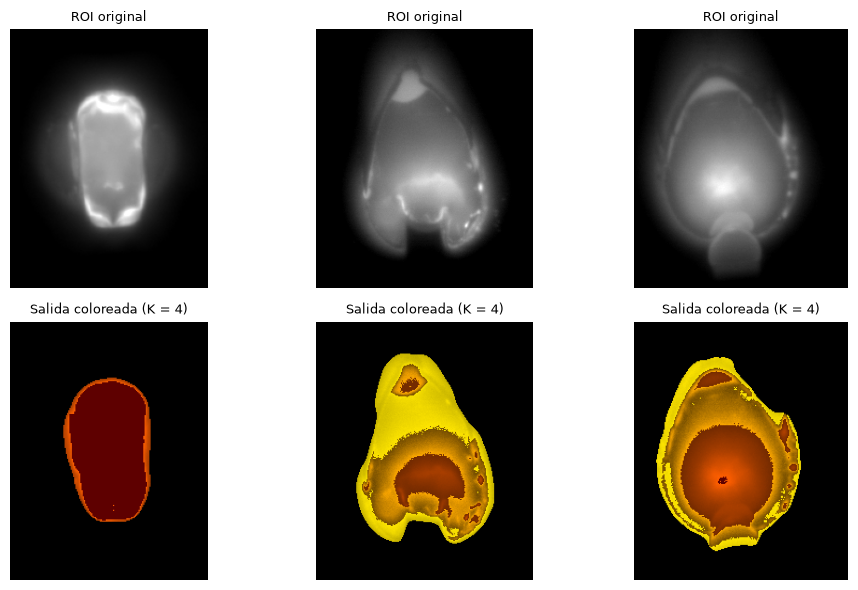

In [35]:
archivos_elegidos = [
    "1764596711507.tiff",
    "1764596817193.tiff",
    "1764596941031.tiff"
]

muestra_out = df_salida[
    df_salida["tiff"].isin(archivos_elegidos)
]

# Crear figura con 2 filas: original y coloreada
fig, ax = plt.subplots(2, len(muestra_out), figsize=(3.4*len(muestra_out), 6), squeeze=False)

for j, (_, f) in enumerate(muestra_out.iterrows()):

    # Leer ROI original
    recorte_orig = leer_frame(RUTA_DATOS / f["tiff"])[f["r0"]:f["r1"], f["c0"]:f["c1"]]

    # Leer TIFF procesado para obtener la máscara
    salida_gris = leer_frame(RUTA_SALIDA / f["archivo"])
    recorte_mascarado = np.where(salida_gris > 0, recorte_orig, 0)

    # Colorear usando K-means
    salida_color = colorear_frame(recorte_mascarado, rangos_finales, COLORES)

    # Fila 1: ROI original
    ax[0, j].imshow(recorte_orig, cmap="gray")
    ax[0, j].set_title("ROI original", fontsize=9)

    # Fila 2: salida coloreada (antes fila 3)
    ax[1, j].imshow(salida_color)
    ax[1, j].set_title(f"Salida coloreada (K = {K_FINAL})", fontsize=9)

    ax[0, j].axis("off")
    ax[1, j].axis("off")

plt.tight_layout()
plt.show()

#### 4.2 Reducción del volumen de datos

Se compara el tamaño del dataset original con el nuevo.

In [36]:
mb = lambda rutas: sum(Path(r).stat().st_size for r in rutas) / 1e6
mb_original = mb(rutas_tiff)
mb_nuevo = mb(RUTA_SALIDA / a for a in df_salida["archivo"])
print(f"Dataset original (todos los TIFF): {len(rutas_tiff):>6} archivos | {mb_original:,.1f} MB")
print(f"Dataset nuevo (TIFF):              {len(df_salida):>6} archivos | {mb_nuevo:,.1f} MB")
print(f"Reducción de archivos: {100*(1-len(df_salida)/len(rutas_tiff)):.1f} % | Reducción de peso: {100*(1-mb_nuevo/mb_original):.1f} %")

Dataset original (todos los TIFF):  41645 archivos | 1,493.2 MB
Dataset nuevo (TIFF):               18624 archivos | 56.0 MB
Reducción de archivos: 55.3 % | Reducción de peso: 96.2 %


# ENTREGABLE FINAL – PROCESAMIENTO DE IMÁGENES TÉRMICAS

## 1. Generación del dataset de imágenes a color
## 2. Análisis del pirómetro por cordón de soldadura
## 3. Detección de outliers mediante One-Class SVM
## 4. Identificación y comparación de imágenes atípicas
## 5. Resultados y conclusiones

In [38]:
# Comprobar si están disponibles los resultados de K-means
# y la función de coloreado del Taller 3.

variables = [
    "K_FINAL",
    "modelos_k",
    "rangos_finales",
    "COLORES",
    "colorear_frame"
]

for nombre in variables:
    disponible = nombre in globals()
    print(f"{nombre}: {'Disponible' if disponible else 'No disponible'}")

# Mostrar el número de clústeres, si está disponible
if "K_FINAL" in globals():
    print("\nK seleccionado:", K_FINAL)

K_FINAL: Disponible
modelos_k: Disponible
rangos_finales: Disponible
COLORES: Disponible
colorear_frame: Disponible

K seleccionado: 4


In [39]:
# ============================================================
# ENTREGABLE FINAL
# GENERACIÓN DE IMÁGENES TIFF Y PNG A COLOR
# Reutilizando la configuración y K-means del Taller 3
# ============================================================

# Porcentaje mínimo de área de la máscara para aceptar la imagen.
MIN_AREA_PCT = 1.0

# Recuperar el modelo K-means seleccionado anteriormente.
centros_finales = modelos_k[K_FINAL]

# ------------------------------------------------------------
# 1. DEFINIR CARPETAS DE SALIDA
# ------------------------------------------------------------

# Carpeta para las imágenes TIFF en escala de grises.
RUTA_SALIDA = RUTA_DATOS / "salida_taller3_tiff"
RUTA_SALIDA.mkdir(parents=True, exist_ok=True)

# Carpeta para las imágenes PNG a color.
RUTA_SALIDA_PNG = RUTA_DATOS / "salida_taller3_png"
RUTA_SALIDA_PNG.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. INICIALIZAR VARIABLES
# ------------------------------------------------------------

resumen_salida = []
sin_senal = 0
mascara_pequena = 0

# ------------------------------------------------------------
# 3. PROCESAR LAS IMÁGENES DE DEPOSICIÓN
# ------------------------------------------------------------

for i, reg in enumerate(registros_deposito, start=1):

    # Leer y preparar la imagen original.
    frame = preparar_frame(reg["ruta"])

    # Descartar imágenes sin señal válida.
    if frame is None:
        sin_senal += 1
        continue

    # Aplicar la segmentación seleccionada en el Taller 3.
    mascara = construir_mascara(frame, **CONFIG_FINAL)

    # Descartar máscaras demasiado pequeñas.
    porcentaje_area = 100 * mascara.sum() / mascara.size

    if porcentaje_area < MIN_AREA_PCT:
        mascara_pequena += 1
        continue

    # --------------------------------------------------------
    # 4. CALCULAR LA LONGITUD DEL MELT POOL
    # --------------------------------------------------------

    filas = np.where(mascara > 0)[0]

    longitud_melt_pool = int(
        filas.max() - filas.min() + 1
    )

    # --------------------------------------------------------
    # 5. GENERAR TIFF EN ESCALA DE GRISES
    # --------------------------------------------------------

    # Agrupar las intensidades utilizando el modelo K-means.
    salida_gris = agrupar_en_grises(
        frame["recorte"],
        mascara,
        centros_finales
    )

    # Mantener el nombre original de la imagen.
    ruta_out = RUTA_SALIDA / f"{reg['ruta'].stem}.tiff"

    # Guardar TIFF.
    guardar_tiff_gris(salida_gris, ruta_out)

    # --------------------------------------------------------
    # 6. GENERAR PNG A COLOR
    # --------------------------------------------------------

    # Conservar únicamente los píxeles de la región segmentada.
    recorte_mascarado = np.where(
        mascara > 0,
        frame["recorte"],
        0
    )

    # Aplicar los colores definidos para los 4 clústeres.
    png_color = colorear_frame(
        recorte_mascarado,
        rangos_finales,
        COLORES
    )

    # Conservar el nombre original, cambiando la extensión.
    ruta_png = RUTA_SALIDA_PNG / f"{reg['ruta'].stem}.png"

    # OpenCV utiliza BGR; convertir desde RGB antes de guardar.
    guardado_correcto = cv2.imwrite(
        str(ruta_png),
        cv2.cvtColor(png_color, cv2.COLOR_RGB2BGR)
    )

    if not guardado_correcto:
        raise OSError(
            f"No se pudo guardar la imagen: {ruta_png}"
        )

    # --------------------------------------------------------
    # 7. GUARDAR INFORMACIÓN DE CADA IMAGEN
    # --------------------------------------------------------

    r0, r1, c0, c1 = frame["roi"]

    resumen_salida.append({
        "archivo": ruta_out.name,
        "archivo_png": ruta_png.name,
        "tiff": reg["ruta"].name,
        "ms_csv": reg["ms_csv"],
        "r0": r0,
        "r1": r1,
        "c0": c0,
        "c1": c1,
        "alto": salida_gris.shape[0],
        "ancho": salida_gris.shape[1],
        "area_mascara": int(mascara.sum()),
        "longitud_melt_pool_px": longitud_melt_pool
    })

    # Mostrar progreso cada 2000 imágenes.
    if i % 2000 == 0:
        print(
            f"Procesadas {i}/{len(registros_deposito)}"
        )

# ------------------------------------------------------------
# 8. GENERAR LOS ARCHIVOS CSV
# ------------------------------------------------------------

# Crear el DataFrame con los resultados.
df_salida = pd.DataFrame(resumen_salida)

# Guardar el resumen de los TIFF.
df_salida.to_csv(
    RUTA_SALIDA / "resumen_tiff.csv",
    index=False
)

# Guardar el resumen de los PNG.
df_salida.to_csv(
    RUTA_SALIDA_PNG / "resumen_png.csv",
    index=False
)

# ------------------------------------------------------------
# 9. MOSTRAR RESULTADOS
# ------------------------------------------------------------

print("\n========== RESULTADOS ==========")

print("K utilizado:", K_FINAL)
print("TIFF generados:", len(df_salida))
print("PNG a color generados:", len(df_salida))
print("Descartados por falta de señal:", sin_senal)
print("Descartados por máscara pequeña:", mascara_pequena)

if not df_salida.empty:
    print(
        "Longitud media del melt pool (px):",
        round(
            df_salida["longitud_melt_pool_px"].mean(),
            2
        )
    )

print("\nCarpeta TIFF:", RUTA_SALIDA)
print("Carpeta PNG:", RUTA_SALIDA_PNG)
print("\nProceso finalizado.")

Procesadas 2000/18624
Procesadas 4000/18624
Procesadas 6000/18624
Procesadas 8000/18624
Procesadas 10000/18624
Procesadas 12000/18624
Procesadas 14000/18624
Procesadas 16000/18624
Procesadas 18000/18624

========== RESULTADOS ==========
K utilizado: 4
TIFF generados: 18624
PNG a color generados: 18624
Descartados por falta de señal: 0
Descartados por máscara pequeña: 0
Longitud media del melt pool (px): 211.42

Carpeta TIFF: C:\Users\juni_\Downloads\ProcesamientoImagenesSe-ales_Taller1-main\ProcesamientoImagenesSe-ales_Taller1-main\Data\images\salida_taller3_tiff
Carpeta PNG: C:\Users\juni_\Downloads\ProcesamientoImagenesSe-ales_Taller1-main\ProcesamientoImagenesSe-ales_Taller1-main\Data\images\salida_taller3_png

Proceso finalizado.


Total de imágenes PNG encontradas: 18624


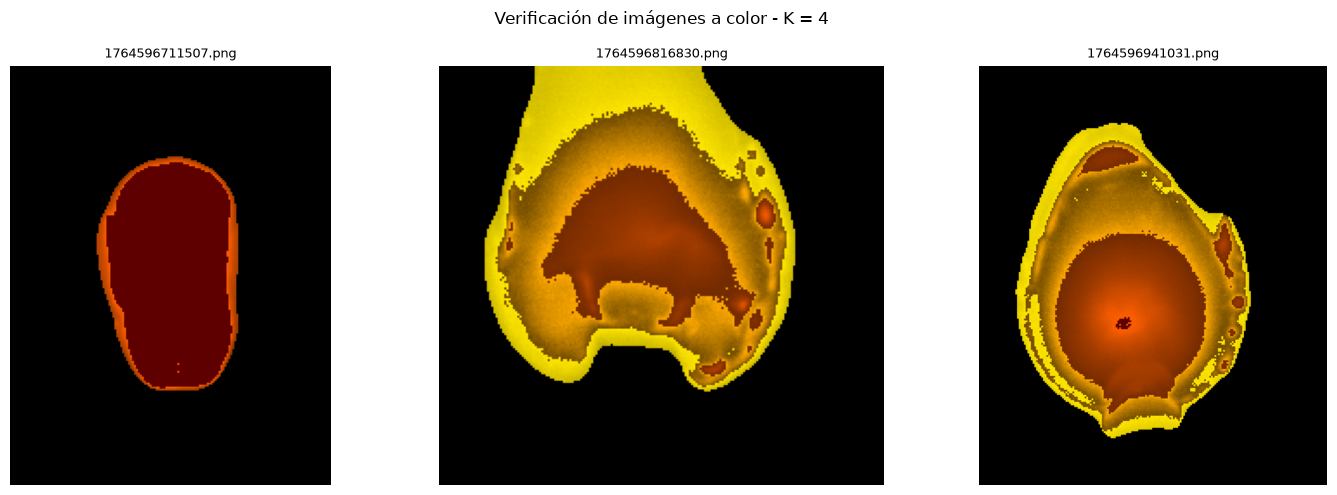

In [40]:
# ============================================================
# VERIFICACIÓN VISUAL DE LAS IMÁGENES PNG A COLOR
# ============================================================

import matplotlib.pyplot as plt
import cv2

# Buscar las imágenes PNG generadas.
archivos_png = sorted(RUTA_SALIDA_PNG.glob("*.png"))

print("Total de imágenes PNG encontradas:", len(archivos_png))

# Seleccionar tres imágenes distribuidas en el dataset.
indices = [
    0,
    len(archivos_png) // 2,
    len(archivos_png) - 1
]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, indice in zip(axes, indices):

    ruta = archivos_png[indice]

    # Leer imagen y convertir de BGR a RGB.
    imagen = cv2.imread(str(ruta))
    imagen_rgb = cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB)

    # Visualizar imagen.
    ax.imshow(imagen_rgb)
    ax.set_title(ruta.name, fontsize=9)
    ax.axis("off")

plt.suptitle("Verificación de imágenes a color - K = 4")
plt.tight_layout()
plt.show()

In [41]:
# ============================================================
# ANÁLISIS DEL PIRÓMETRO - PASO 1
# Identificar las variables de temperatura y cordón
# ============================================================

# Buscar únicamente columnas relacionadas con el pirómetro,
# temperatura, tiempo y posición de deposición.

palabras_clave = [
    "pyro", "pir", "temp", "thermal",
    "timestamp", "position", "pos",
    "track", "layer", "bead", "pass"
]

columnas_interes = [
    columna
    for columna in df_csv.columns
    if any(
        palabra in columna.lower()
        for palabra in palabras_clave
    )
]

print("COLUMNAS RELEVANTES DEL CSV:")
for columna in columnas_interes:
    print("-", columna)

print("\nPRIMERAS 5 FILAS:")
print(df_csv[columnas_interes].head().to_string(index=False))

COLUMNAS RELEVANTES DEL CSV:
- timestamp*
- ExposureTime_i
- PyrometerTemperature
- ProcessTemperature
- deposito_activo

PRIMERAS 5 FILAS:
  timestamp*  ExposureTime_i  PyrometerTemperature  ProcessTemperature  deposito_activo
1.764597e+09              60                  6547          613.015094            False
1.764597e+09              60                  6547          613.015094            False
1.764597e+09              60                  6561          613.913207            False
1.764597e+09              60                  6561          613.913207            False
1.764597e+09              60                  6554          613.464151            False


In [42]:
# ============================================================
# IDENTIFICAR INTERVALOS CONSECUTIVOS DE DEPOSICIÓN ACTIVA
# ============================================================

import pandas as pd

# Ordenar las mediciones cronológicamente.
df_piro = df_csv.sort_values("timestamp*").copy()

# Identificar cuándo cambia el estado de deposición.
df_piro["grupo_intervalo"] = (
    df_piro["deposito_activo"]
    .ne(df_piro["deposito_activo"].shift())
    .cumsum()
)

# Conservar únicamente los intervalos de deposición activa.
df_activo = df_piro[df_piro["deposito_activo"] == True].copy()

# Resumir cada intervalo consecutivo.
resumen_cordones = (
    df_activo
    .groupby("grupo_intervalo")
    .agg(
        inicio=("timestamp*", "min"),
        fin=("timestamp*", "max"),
        mediciones=("PyrometerTemperature", "size"),
        temperatura_media=("PyrometerTemperature", "mean"),
        temperatura_min=("PyrometerTemperature", "min"),
        temperatura_max=("PyrometerTemperature", "max")
    )
    .reset_index(drop=True)
)

# Calcular duración de cada intervalo.
resumen_cordones["duracion_s"] = (
    resumen_cordones["fin"] - resumen_cordones["inicio"]
)

print("Intervalos de deposición encontrados:", len(resumen_cordones))

print("\nRESUMEN:")
print(
    resumen_cordones[
        [
            "mediciones",
            "duracion_s",
            "temperatura_media",
            "temperatura_min",
            "temperatura_max"
        ]
    ].round(2).to_string(index=False)
)

Intervalos de deposición encontrados: 6

RESUMEN:
 mediciones  duracion_s  temperatura_media  temperatura_min  temperatura_max
       4703       24.73           17653.04            17152            25073
       4663       24.53           18535.91             6553            21816
       4633       24.35           18434.86             6552            23621
       4601       24.19           18234.68             6547            21477
       4565       24.00           18277.99             6547            22399
       4512       23.72           18273.94             6548            21767


In [43]:
# ============================================================
# DETECCIÓN DE OUTLIERS DEL PIRÓMETRO POR CORDÓN
# Método: One-Class SVM
# ============================================================

import numpy as np
import pandas as pd

from sklearn.svm import OneClassSVM
from sklearn.preprocessing import StandardScaler

# Crear una columna para identificar cada cordón.
grupos = sorted(df_activo["grupo_intervalo"].unique())

mapa_cordones = {
    grupo: numero
    for numero, grupo in enumerate(grupos, start=1)
}

df_activo["cordon"] = (
    df_activo["grupo_intervalo"].map(mapa_cordones)
)

# Inicializar columna de resultados.
df_activo["outlier"] = False

# Parámetros del modelo.
NU = 0.03
GAMMA = "scale"

# Analizar cada cordón de forma independiente.
for cordon in sorted(df_activo["cordon"].unique()):

    # Seleccionar las mediciones del cordón.
    datos = df_activo[
        df_activo["cordon"] == cordon
    ]

    # Utilizar la temperatura del pirómetro.
    X = datos[["PyrometerTemperature"]].to_numpy()

    # Normalizar los datos del cordón.
    escalador = StandardScaler()
    X_norm = escalador.fit_transform(X)

    # Entrenar One-Class SVM.
    modelo = OneClassSVM(
        kernel="rbf",
        gamma=GAMMA,
        nu=NU
    )

    predicciones = modelo.fit_predict(X_norm)

    # -1 indica valor atípico.
    df_activo.loc[
        datos.index, "outlier"
    ] = predicciones == -1

# ============================================================
# RESUMEN DE ANOMALÍAS
# ============================================================

resumen_outliers = (
    df_activo
    .groupby("cordon")
    .agg(
        mediciones=("outlier", "size"),
        outliers=("outlier", "sum"),
        temperatura_media=("PyrometerTemperature", "mean")
    )
    .reset_index()
)

resumen_outliers["porcentaje_outliers"] = (
    100
    * resumen_outliers["outliers"]
    / resumen_outliers["mediciones"]
)

print("RESULTADOS DE ONE-CLASS SVM")
print(
    resumen_outliers.round(2).to_string(index=False)
)

print(
    "\nTotal de outliers:",
    int(df_activo["outlier"].sum())
)

RESULTADOS DE ONE-CLASS SVM
 cordon  mediciones  outliers  temperatura_media  porcentaje_outliers
      1        4703       181           17653.04                 3.85
      2        4663       164           18535.91                 3.52
      3        4633       208           18434.86                 4.49
      4        4601       138           18234.68                 3.00
      5        4565       157           18277.99                 3.44
      6        4512       173           18273.94                 3.83

Total de outliers: 1021


In [44]:
# ============================================================
# RELACIONAR OUTLIERS DEL PIRÓMETRO CON IMÁGENES PNG
# ============================================================

import numpy as np
import pandas as pd

# Cargar el resumen de imágenes generado anteriormente.
df_imagenes = pd.read_csv(
    RUTA_SALIDA_PNG / "resumen_png.csv"
)

# Ordenar las mediciones del pirómetro por tiempo.
df_temperaturas = df_activo[
    [
        "timestamp*",
        "cordon",
        "PyrometerTemperature",
        "outlier"
    ]
].copy()

df_temperaturas = df_temperaturas.sort_values("timestamp*")

# El Taller 3 registra el tiempo de cada imagen en ms_csv.
# Convertirlo a segundos para compararlo con timestamp*.
df_imagenes["tiempo_s"] = (
    pd.to_numeric(df_imagenes["ms_csv"]) / 1000
)

df_imagenes = df_imagenes.sort_values("tiempo_s")

# Asociar cada imagen con la medición más cercana.
# Se permite una diferencia máxima de 3 milisegundos.
df_comparacion = pd.merge_asof(
    df_imagenes,
    df_temperaturas,
    left_on="tiempo_s",
    right_on="timestamp*",
    direction="nearest",
    tolerance=0.003
)

# Conservar únicamente imágenes con una medición asociada.
df_comparacion = df_comparacion.dropna(
    subset=["cordon", "PyrometerTemperature", "outlier"]
).copy()

# Asegurar los tipos correctos.
df_comparacion["cordon"] = (
    df_comparacion["cordon"].astype(int)
)

df_comparacion["outlier"] = (
    df_comparacion["outlier"].astype(bool)
)

# Guardar el resultado para el informe.
ruta_comparacion = (
    RUTA_SALIDA_PNG / "imagenes_outliers_pirómetro.csv"
)

df_comparacion.to_csv(
    ruta_comparacion,
    index=False
)

# Resumir las imágenes vinculadas.
resumen_imagenes = (
    df_comparacion
    .groupby("cordon")
    .agg(
        imagenes=("archivo_png", "size"),
        imagenes_outlier=("outlier", "sum")
    )
)

print("IMÁGENES VINCULADAS POR CORDÓN")
print(resumen_imagenes.to_string())

print("\nTotal de imágenes vinculadas:", len(df_comparacion))
print("Imágenes asociadas a outliers:", int(df_comparacion["outlier"].sum()))
print("Archivo generado:", ruta_comparacion)

IMÁGENES VINCULADAS POR CORDÓN
        imagenes  imagenes_outlier
cordon                            
1           3164               127
2           3138               113
3           3143               146
4           3113                95
5           3046               106
6           3020               118

Total de imágenes vinculadas: 18624
Imágenes asociadas a outliers: 705
Archivo generado: C:\Users\juni_\Downloads\ProcesamientoImagenesSe-ales_Taller1-main\ProcesamientoImagenesSe-ales_Taller1-main\Data\images\salida_taller3_png\imagenes_outliers_pirómetro.csv


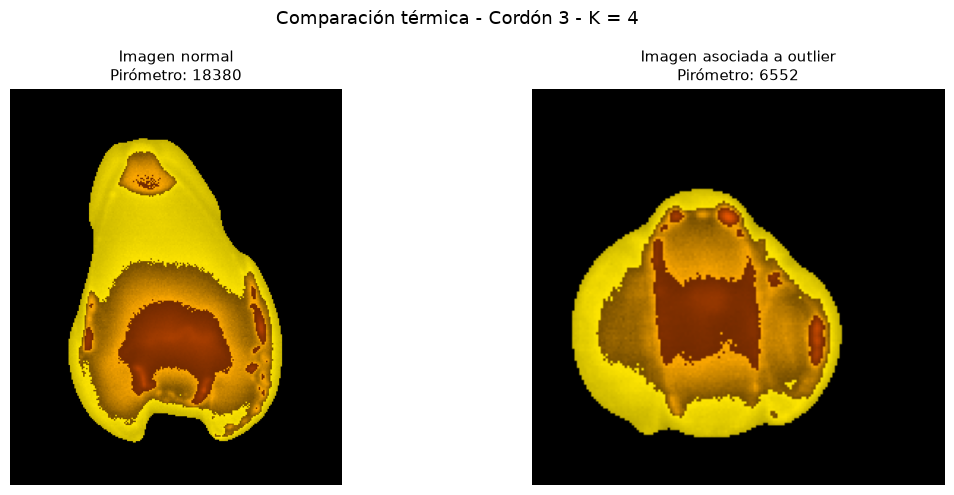

IMAGEN NORMAL:
1764596794649.png
Temperatura: 18380

IMAGEN ASOCIADA A OUTLIER:
1764596793526.png
Temperatura: 6552


In [45]:
# ============================================================
# COMPARACIÓN DE IMÁGENES NORMALES Y ANÓMALAS
# ============================================================

import cv2
import matplotlib.pyplot as plt

# Elegir el cordón 3, que presentó el mayor porcentaje de outliers.
CORDON = 3

datos_cordon = df_comparacion[
    df_comparacion["cordon"] == CORDON
].copy()

# Seleccionar la imagen anómala con menor lectura del pirómetro.
anomalias = datos_cordon[datos_cordon["outlier"]]

imagen_anomala = anomalias.loc[
    anomalias["PyrometerTemperature"].idxmin()
]

# Seleccionar una imagen normal cercana a la mediana térmica.
normales = datos_cordon[~datos_cordon["outlier"]]

temperatura_mediana = normales["PyrometerTemperature"].median()

indice_normal = (
    normales["PyrometerTemperature"] - temperatura_mediana
).abs().idxmin()

imagen_normal = normales.loc[indice_normal]

# ------------------------------------------------------------
# VISUALIZACIÓN
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ejemplos = [
    (imagen_normal, "Imagen normal"),
    (imagen_anomala, "Imagen asociada a outlier")
]

for ax, (registro, titulo) in zip(axes, ejemplos):

    ruta = RUTA_SALIDA_PNG / registro["archivo_png"]

    imagen = cv2.imread(str(ruta))

    if imagen is None:
        raise FileNotFoundError(f"No se pudo leer: {ruta}")

    imagen_rgb = cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB)

    ax.imshow(imagen_rgb)

    ax.set_title(
        f"{titulo}\n"
        f"Pirómetro: {registro['PyrometerTemperature']:.0f}",
        fontsize=11
    )

    ax.axis("off")

plt.suptitle(
    f"Comparación térmica - Cordón {CORDON} - K = {K_FINAL}",
    fontsize=13
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# MOSTRAR ARCHIVOS SELECCIONADOS
# ------------------------------------------------------------

print("IMAGEN NORMAL:")
print(imagen_normal["archivo_png"])
print("Temperatura:", imagen_normal["PyrometerTemperature"])

print("\nIMAGEN ASOCIADA A OUTLIER:")
print(imagen_anomala["archivo_png"])
print("Temperatura:", imagen_anomala["PyrometerTemperature"])

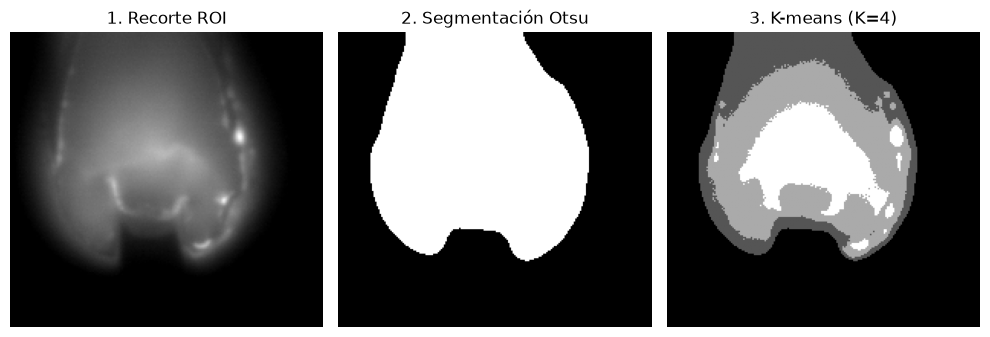

In [46]:
import matplotlib.pyplot as plt
import numpy as np

# Seleccionar una imagen del conjunto de deposición activa.
reg = registros_deposito[len(registros_deposito) // 2]

# Recuperar el recorte original.
frame = preparar_frame(reg["ruta"])

# Aplicar la segmentación seleccionada.
mascara = construir_mascara(frame, **CONFIG_FINAL)

# Aplicar K-means con la configuración final.
imagen_kmeans = agrupar_en_grises(
    frame["recorte"],
    mascara,
    modelos_k[K_FINAL]
)

# Crear figura comparativa.
fig, axes = plt.subplots(1, 3, figsize=(10, 3.5))

axes[0].imshow(frame["recorte"], cmap="gray")
axes[0].set_title("1. Recorte ROI")

axes[1].imshow(mascara, cmap="gray")
axes[1].set_title("2. Segmentación Otsu")

axes[2].imshow(imagen_kmeans, cmap="gray")
axes[2].set_title("3. K-means (K=4)")

for ax in axes:
    ax.axis("off")

plt.tight_layout()

# Guardar la figura para insertarla en el informe.
plt.savefig(
    RUTA_SALIDA / "comparacion_procesamiento.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

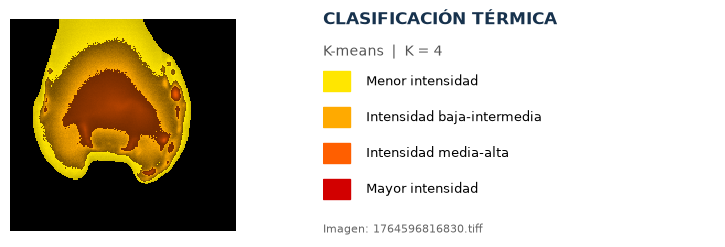

Figura guardada en: C:\Users\juni_\Downloads\ProcesamientoImagenesSe-ales_Taller1-main\ProcesamientoImagenesSe-ales_Taller1-main\Data\images\salida_taller3_png\figura_dataset_color_horizontal.png


In [48]:
# ============================================================
# FIGURA HORIZONTAL - DATASET A COLOR K-MEANS
# ============================================================

import cv2
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from pathlib import Path

# 1. Cargar una imagen real del dataset procesado.
nombre_imagen = "1764596816830.png"
ruta_imagen = RUTA_SALIDA_PNG / nombre_imagen

imagen_bgr = cv2.imread(str(ruta_imagen))

if imagen_bgr is None:
    raise FileNotFoundError(f"No se pudo leer: {ruta_imagen}")

imagen_rgb = cv2.cvtColor(imagen_bgr, cv2.COLOR_BGR2RGB)

# 2. Recuperar la paleta de colores original.
colores_hex = [
    "#{:02X}{:02X}{:02X}".format(*color)
    for color in COLORES[:K_FINAL]
]

etiquetas = [
    "Menor intensidad",
    "Intensidad baja-intermedia",
    "Intensidad media-alta",
    "Mayor intensidad"
]

# 3. Crear diseño horizontal.
fig = plt.figure(figsize=(8, 2.8), facecolor="white")

# Imagen a la izquierda.
ax_img = fig.add_axes([0.03, 0.12, 0.40, 0.76])
ax_img.imshow(imagen_rgb, interpolation="nearest")
ax_img.axis("off")

# Información a la derecha.
ax_info = fig.add_axes([0.48, 0.10, 0.49, 0.80])
ax_info.axis("off")

ax_info.text(
    0, 0.95,
    "CLASIFICACIÓN TÉRMICA",
    fontsize=12,
    fontweight="bold",
    color="#17324D",
    transform=ax_info.transAxes
)

ax_info.text(
    0, 0.81,
    f"K-means  |  K = {K_FINAL}",
    fontsize=10,
    color="#555555",
    transform=ax_info.transAxes
)

# Leyenda vertical de los cuatro niveles.
for i, (color, etiqueta) in enumerate(zip(colores_hex, etiquetas)):

    y = 0.65 - i * 0.16

    ax_info.add_patch(
        plt.Rectangle(
            (0, y),
            0.07,
            0.09,
            color=color,
            transform=ax_info.transAxes
        )
    )

    ax_info.text(
        0.11, y + 0.045,
        etiqueta,
        va="center",
        fontsize=9,
        transform=ax_info.transAxes
    )

# Nombre original de la imagen.
ax_info.text(
    0, 0.02,
    f"Imagen: {Path(nombre_imagen).stem}.tiff",
    fontsize=8,
    color="#666666",
    transform=ax_info.transAxes
)

# 4. Guardar en alta resolución.
ruta_figura = (
    RUTA_SALIDA_PNG / "figura_dataset_color_horizontal.png"
)

fig.savefig(
    ruta_figura,
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.08,
    facecolor="white"
)

plt.show()

print("Figura guardada en:", ruta_figura)

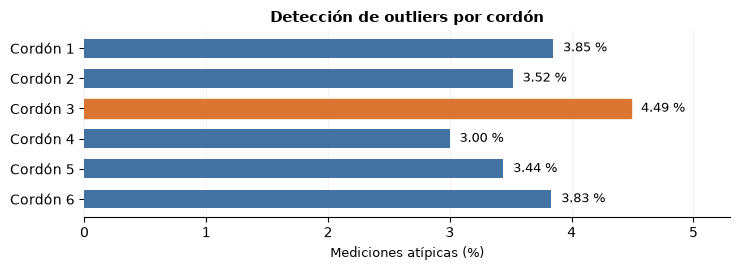

Figura guardada en: C:\Users\juni_\Downloads\ProcesamientoImagenesSe-ales_Taller1-main\ProcesamientoImagenesSe-ales_Taller1-main\Data\images\salida_taller3_png\outliers_por_cordon.png


In [49]:
import matplotlib.pyplot as plt

# Recuperar los resultados de One-Class SVM.
datos = resumen_outliers.sort_values("cordon")

fig, ax = plt.subplots(figsize=(7.5, 2.8))

# Crear barras horizontales.
barras = ax.barh(
    [f"Cordón {c}" for c in datos["cordon"]],
    datos["porcentaje_outliers"],
    color="#4472A0",
    height=0.62
)

# Resaltar el cordón con mayor porcentaje.
indice_max = datos["porcentaje_outliers"].idxmax()

for barra, indice in zip(barras, datos.index):
    if indice == indice_max:
        barra.set_color("#D97732")

# Mostrar porcentaje al final de cada barra.
for barra in barras:
    valor = barra.get_width()
    ax.text(
        valor + 0.08,
        barra.get_y() + barra.get_height() / 2,
        f"{valor:.2f} %",
        va="center",
        fontsize=9
    )

ax.invert_yaxis()
ax.set_xlim(0, 5.3)
ax.set_xlabel("Mediciones atípicas (%)", fontsize=9)
ax.set_title(
    "Detección de outliers por cordón",
    fontsize=11,
    fontweight="bold"
)

ax.spines[["top", "right", "left"]].set_visible(False)
ax.grid(axis="x", alpha=0.15)
ax.set_axisbelow(True)

plt.tight_layout()

ruta_figura = RUTA_SALIDA_PNG / "outliers_por_cordon.png"

plt.savefig(
    ruta_figura,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Figura guardada en:", ruta_figura)

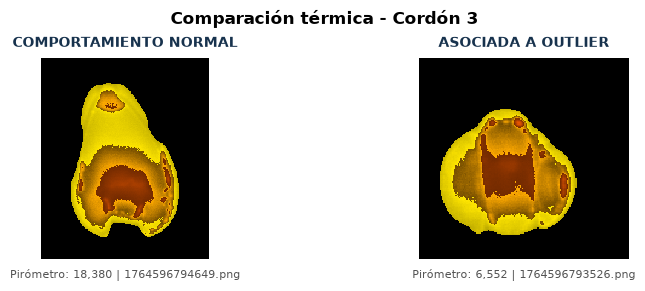

Figura guardada en: C:\Users\juni_\Downloads\ProcesamientoImagenesSe-ales_Taller1-main\ProcesamientoImagenesSe-ales_Taller1-main\Data\images\salida_taller3_png\comparacion_normal_outlier.png


: 

In [ ]:
import cv2
import matplotlib.pyplot as plt

# Imágenes reales del cordón 3
archivos = [
    "1764596794649.png",
    "1764596793526.png"
]

titulos = [
    "COMPORTAMIENTO NORMAL",
    "ASOCIADA A OUTLIER"
]

lecturas = [18380, 6552]

fig, axes = plt.subplots(
    1, 2,
    figsize=(8, 3),
    facecolor="white"
)

for ax, archivo, titulo, lectura in zip(
    axes, archivos, titulos, lecturas
):
    ruta = RUTA_SALIDA_PNG / archivo

    imagen = cv2.imread(str(ruta))

    if imagen is None:
        raise FileNotFoundError(f"No existe: {ruta}")

    imagen = cv2.cvtColor(
        imagen, cv2.COLOR_BGR2RGB
    )

    ax.imshow(imagen, interpolation="nearest")
    ax.axis("off")

    ax.set_title(
        titulo,
        fontsize=10,
        fontweight="bold",
        color="#17324D",
        pad=8
    )

    ax.text(
        0.5, -0.05,
        f"Pirómetro: {lectura:,} | {archivo}",
        transform=ax.transAxes,
        ha="center",
        va="top",
        fontsize=8,
        color="#555555"
    )

fig.suptitle(
    "Comparación térmica - Cordón 3",
    fontsize=12,
    fontweight="bold",
    y=0.99
)

plt.subplots_adjust(
    left=0.02,
    right=0.98,
    top=0.83,
    bottom=0.16,
    wspace=0.08
)

ruta_figura = (
    RUTA_SALIDA_PNG /
    "comparacion_normal_outlier.png"
)

fig.savefig(
    ruta_figura,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Figura guardada en:", ruta_figura)